Inspect the structure & dimensions:


In [7]:
import pandas as pd
import numpy as np
from IPython.display import display
df=pd.read_csv("CreditScore.csv")
print(" Dataset Shape",df.shape)
display(df.head())
print("INformation of the Data")
df.info()
print("Description of the dataset")
df.describe()

 Dataset Shape (150000, 13)


/tmp/ipykernel_7523/3776640148.py:4: DtypeWarning: Columns (3: Gender) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("CreditScore.csv")


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Gender,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,f,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,m,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,f,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,m,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,f,49,1,0.024926,63588.0,7,0,1,0,0.0


INformation of the Data
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 13 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   Gender                                307 non-null     str    
 4   Age                                   150000 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 6   DebtRatio                             150000 non-null  float64
 7   MonthlyIncome                         120269 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 9   NumberOfTimes90DaysLate               150000 non-null  int64  
 10  NumberRealEstateLoansOrLines          150000 non-null  

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Initial Data Quality Check:


In [11]:
print("Checking null values :")
display(df.isnull().sum())
print("Duplicated value :")
display(df.duplicated().sum())
# 1. Check for duplicates excluding the 'Id' column
true_dup=df.drop(columns=['Id']).duplicated().sum()
print(f"Ture duplicates : {true_dup}")

Checking null values :


Id                                           0
SeriousDlqin2yrs                             0
RevolvingUtilizationOfUnsecuredLines         0
Gender                                  149693
Age                                          0
NumberOfTime30-59DaysPastDueNotWorse         0
DebtRatio                                    0
MonthlyIncome                            29731
NumberOfOpenCreditLinesAndLoans              0
NumberOfTimes90DaysLate                      0
NumberRealEstateLoansOrLines                 0
NumberOfTime60-89DaysPastDueNotWorse         0
NumberOfDependents                        3924
dtype: int64

Duplicated value :


np.int64(0)

Ture duplicates : 608


In [17]:
print("\n--- Missing Values Summary ---")
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_df)


--- Missing Values Summary ---


,Missing Count,Missing Percentage (%)
Id,0,0.000000
SeriousDlqin2yrs,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
Gender,149693,99.795333
Age,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
DebtRatio,0,0.000000
MonthlyIncome,29731,19.820667
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000


In [19]:
# Display only columns that actually have missing values, sorted by count
missing_df=missing_df[missing_df['Missing Count']>0].sort_values(by='Missing Count', ascending=False)
display(missing_df)

,Missing Count,Missing Percentage (%)
Gender,149693,99.795333
MonthlyIncome,29731,19.820667
NumberOfDependents,3924,2.616000


In [21]:
# 3. Target Variable Distribution (SeriousDlqin2yrs)
print("\n--- Target Variable Distribution (SeriousDlqin2yrs) ---")
target_summary=pd.DataFrame({
    'Count':df['SeriousDlqin2yrs'].value_counts(),
    'Percentage (%)':(df['SeriousDlqin2yrs'].value_counts(normalize=True)*100).round(2)
})
display(target_summary)


--- Target Variable Distribution (SeriousDlqin2yrs) ---


,Count,Percentage (%)
SeriousDlqin2yrs,,
0,139974,93.32
1,10026,6.68


In [25]:
print("\n--- Suspicious Data Checks ---")
print(f"Borrowers with Age == 0: {(df['Age'] == 0).sum()}")
print(f"Borrowers with late payment code >= 90: {(df['NumberOfTime30-59DaysPastDueNotWorse'] >= 90).sum()}")


--- Suspicious Data Checks ---
Borrowers with Age == 0: 1
Borrowers with late payment code >= 90: 269


In [26]:
print("--- 1. Age Anomalies ---")
zero_age_count = (df['Age'] == 0).sum()
print(f"Number of borrowers with Age == 0: {zero_age_count}")

print("\n--- 2. Gender Breakdown ---")
# Value counts including NaN (missing) values
print(df['Gender'].value_counts(dropna=False))

print("\n--- 3. Suspicious Late-Payment Values (Value >= 90) ---")
# Checking occurrences of extreme values like 96 or 98
display(df[df['NumberOfTime30-59DaysPastDueNotWorse'] >= 90][
    ['NumberOfTime30-59DaysPastDueNotWorse', 
     'NumberOfTime60-89DaysPastDueNotWorse', 
     'NumberOfTimes90DaysLate']
].head(10))

print(f"Total rows where past-due value is >= 90: {(df['NumberOfTime30-59DaysPastDueNotWorse'] >= 90).sum()}")


--- 1. Age Anomalies ---
Number of borrowers with Age == 0: 1

--- 2. Gender Breakdown ---
Gender
NaN    149693
m         223
f          84
Name: count, dtype: int64

--- 3. Suspicious Late-Payment Values (Value >= 90) ---


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
1733,98,98,98
2286,98,98,98
3884,98,98,98
4417,98,98,98
4705,98,98,98
5073,98,98,98
6280,98,98,98
7032,98,98,98
7117,98,98,98
7687,98,98,98


Total rows where past-due value is >= 90: 269


--- 5-Year Age Groups & Default Rate ---


,AgeGroup,Total_Borrowers,Defaulters,Default_Rate_pct
0,20-24,2074,217,10.46
1,25-29,6746,818,12.13
2,30-34,10419,1115,10.70
3,35-39,12764,1220,9.56
4,40-44,15799,1365,8.64
5,45-49,18578,1513,8.14
6,50-54,18198,1337,7.35
7,55-59,17103,941,5.50
8,60-64,17125,718,4.19
9,65-69,11780,332,2.82


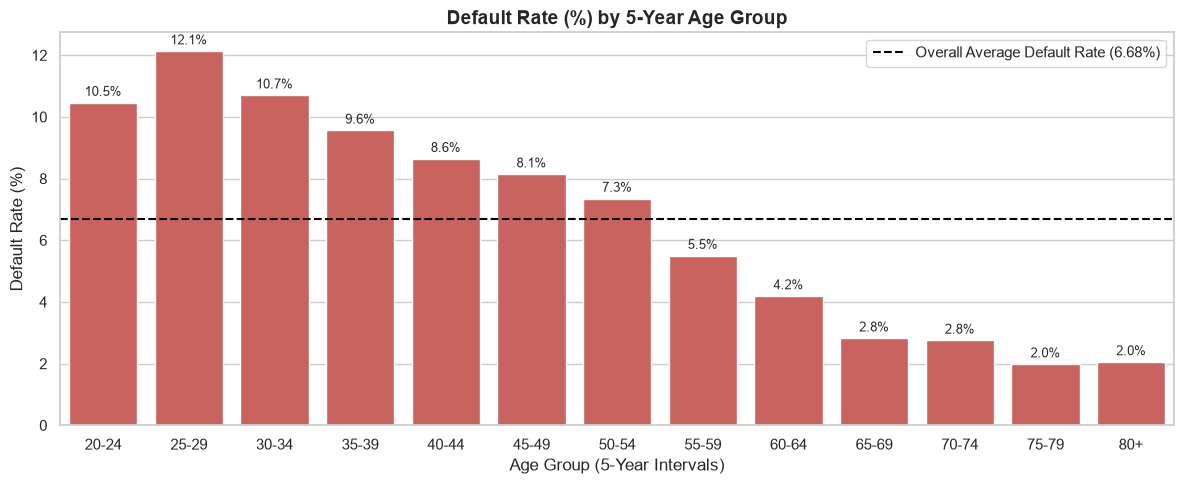

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define 5-year age bins (ignoring the single invalid Age == 0)
bins = list(range(20, 85, 5)) + [110]
labels = [f"{i}-{i+4}" for i in range(20, 80, 5)] + ["80+"]

# 2. Create the 5-year Age Group column
df_age = df[df['Age'] > 0].copy()
df_age['AgeGroup'] = pd.cut(df_age['Age'], bins=bins, labels=labels, right=False)

# 3. Calculate Defaulter statistics per Age Group
age_defaulters = df_age.groupby('AgeGroup', observed=False)['SeriousDlqin2yrs'].agg(
    Total_Borrowers='count',
    Defaulters='sum',
    Default_Rate_pct=lambda x: (x.mean() * 100)
).reset_index()

# Round default rate for display
age_defaulters['Default_Rate_pct'] = age_defaulters['Default_Rate_pct'].round(2)

print("--- 5-Year Age Groups & Default Rate ---")
display(age_defaulters)

# 4. Plot Default Rate by 5-Year Age Group
plt.figure(figsize=(12, 5))
ax = sns.barplot(data=age_defaulters, x='AgeGroup', y='Default_Rate_pct', color='#d9534f')

plt.title('Default Rate (%) by 5-Year Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group (5-Year Intervals)', fontsize=12)
plt.ylabel('Default Rate (%)', fontsize=12)
plt.axhline(6.68, color='black', linestyle='--', label='Overall Average Default Rate (6.68%)')
plt.legend()

# Annotate each bar with the percentage
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%", 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()


Task 4.1:"Explore the distribution of SeriousDlqin2yrs... For every important chart, write the key insight in 1–2 sentences."

,Count,Percentage (%)
SeriousDlqin2yrs,,
0,139974,93.32
1,10026,6.68


/tmp/ipykernel_7523/765495807.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='SeriousDlqin2yrs', palette=['#2b5c8f', '#d9534f'])


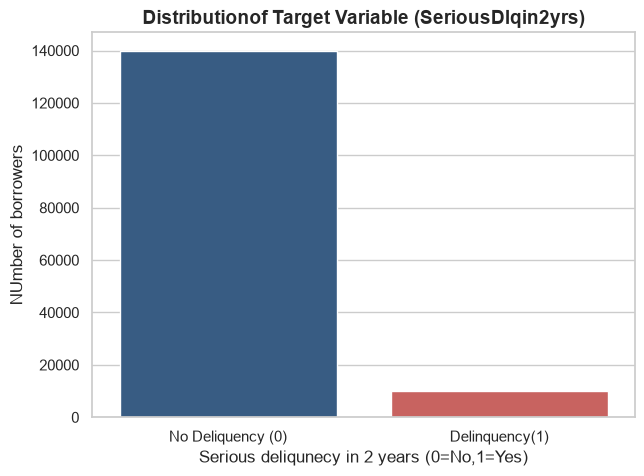

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import set_theme

#set visual style
sns.set_theme(style='whitegrid')
display(target_summary)
#creaet a plot 
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='SeriousDlqin2yrs', palette=['#2b5c8f', '#d9534f'])
plt.title("Distributionof Target Variable (SeriousDlqin2yrs)",fontsize=14,fontweight='bold')
plt.xlabel('Serious deliqunecy in 2 years (0=No,1=Yes)',fontsize=12)
plt.ylabel("NUmber of borrowers",fontsize=12)
plt.xticks([0,1],["No Deliquency (0)",'Delinquency(1)'])
plt.show()